# Module 06 — RNN (recurrence · backpropagation through time · truncation · gradient clipping)

Every network so far has read a fixed-size input: a 2-D point, a 28×28 digit, a 32×32 photo.
Language, speech and music are **sequences** — of any length, where what matters about the
tenth word can depend on the first. In 1990 Jeffrey Elman, a linguist at UC San Diego, showed
what a network that reads one step at a time could discover on its own: given a stream of
letters with no spaces, it learned where the words began. The network was **recurrent**: at
every step it combined the new input with a copy of its own previous hidden state — its memory —
using the *same* weights every time. The same year Paul Werbos published the training method
for such networks in full: unroll the recurrence into one deep network whose layers share their
weights, and backpropagate through it. **Backpropagation through time.**

This notebook builds both. The **RNN layer** (forward over a whole sequence, backpropagation
through time with optional **truncation**) and **gradient-norm clipping** join `nanograd` in
both languages. Two toys show what a recurrent network can and cannot learn — an **echo** that
must remember a symbol for $d$ steps, and a **counter** that must track a running total
forever — and why: the gradient through time shrinks or grows geometrically, and a network can
only learn to remember as far back as its training gradient reaches. Then a character-level
language model of Shakespeare, Elman's word-boundary experiment redone on it, and the framework
mirrors.

In [1]:
import os, sys, math, time
# Windows + conda: conda's MKL (via LLVM OpenMP) and pip's PyTorch each bring
# an OpenMP runtime, and two in one process crash whichever loads first.
# Running MKL single-threaded keeps it from loading one at all; the long
# character-level training here is cached, so the cost is small. (A no-op
# wherever NumPy uses OpenBLAS instead of MKL.)
os.environ.setdefault('MKL_THREADING_LAYER', 'SEQUENTIAL')
import numpy as np
import matplotlib.pyplot as plt

# Locate the repo root whether Jupyter was launched from it or the module folder.
def _find_repo():
    here = os.getcwd()
    cands = [here] + [os.path.abspath(os.path.join(here, *(['..'] * k))) for k in range(1, 6)]
    for base in cands:
        if os.path.isdir(os.path.join(base, 'lib', 'python', 'nanograd')):
            return base
    return here

REPO = _find_repo()
TOPIC = os.path.join(REPO, 'topics', '06-rnn')
sys.path.insert(0, os.path.join(REPO, 'lib', 'python'))   # nanograd
sys.path.insert(0, os.path.join(TOPIC, 'python'))          # canonical rnn.py
sys.path.insert(0, os.path.join(TOPIC, 'tests'))           # check_utils
sys.path.insert(0, os.path.join(REPO, 'data'))             # get_shakespeare

import nanograd as ng
import rnn as canon
from nanograd.rng import Rng
from check_utils import rel_error, eval_numerical_gradient, eval_numerical_gradient_array
np.set_printoptions(precision=4, suppress=True)
SYM = 'ABCD'                                               # the echo toy's alphabet, for printing
print('new in nanograd:', ['RNN', 'clip_grad_norm'], '+ RNN.backward(dH, truncate=k)')

new in nanograd: ['RNN', 'clip_grad_norm'] + RNN.backward(dH, truncate=k)


## 1. A network that reads one step at a time

Take the word "hello" and a vocabulary of four characters, `h e l o`. Each character enters as
a **one-hot** vector $x^{\langle t\rangle}$ — all zeros except a 1 at its index. The network
keeps a **hidden state** $h^{\langle t\rangle}$, a vector of $n_h$ numbers, and updates it at
every step from the new input and its own previous value:

$$z^{\langle t\rangle} = x^{\langle t\rangle} W_{xh} + h^{\langle t-1\rangle} W_{hh} + b_h, \qquad
h^{\langle t\rangle} = \tanh\big(z^{\langle t\rangle}\big), \qquad
\hat{y}^{\langle t\rangle} = \mathrm{softmax}\big(h^{\langle t\rangle} W_{hy} + b_y\big).$$

Reading "h e l l", it should predict "e l l o" — and notice what that requires. After the first
`l` the answer is `l`; after the second it is `o`. The input is the same both times; only the
**state** differs. $W_{xh}$, $W_{hh}$ and $b_h$ are the same at every step: that is the whole idea
of a recurrent network, and it is Module 03's weight sharing applied across time instead of
across an image. The network has the same number of parameters for a four-letter word and a
four-million-letter book.

t=0: read 'h'  h=[ 0.719  0.587 -0.386]  predicts 'l' (p=0.44; the answer is 'e')
t=1: read 'e'  h=[ 0.921  0.121 -0.256]  predicts 'l' (p=0.38; the answer is 'l')
t=2: read 'l'  h=[ 0.553  0.918 -0.469]  predicts 'l' (p=0.45; the answer is 'l')
t=3: read 'l'  h=[ 0.511  0.934 -0.552]  predicts 'l' (p=0.43; the answer is 'o')

40 parameters, whatever the length of the text. The two l's get different states: [ 0.553  0.918 -0.469] vs [ 0.511  0.934 -0.552]


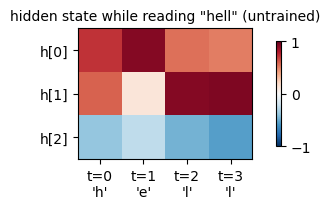

In [2]:
vocab = 'helo'
ids = [vocab.index(c) for c in 'hello']
X1 = np.eye(4)[ids[:-1]]                       # one-hot 'h', 'e', 'l', 'l': (4 steps, 4)
n_h = 3
r = Rng(0)
Wxh, Whh, Why = np.empty((4, n_h)), np.empty((n_h, n_h)), np.empty((n_h, 4))
for W in (Wxh, Whh, Why):
    ng.xavier_normal(W, r)
bh, by = np.zeros(n_h), np.zeros(4)

def rnn_step(x, h_prev):
    return np.tanh(x @ Wxh + h_prev @ Whh + bh)   # the same weights at every step

h, hs = np.zeros(n_h), []
for t in range(4):
    h = rnn_step(X1[t], h)
    hs.append(h)
    p = np.exp(h @ Why + by); p /= p.sum()
    print(f"t={t}: read {vocab[ids[t]]!r}  h={np.round(h, 3)}  predicts {vocab[p.argmax()]!r} "
          f"(p={p.max():.2f}; the answer is {vocab[ids[t + 1]]!r})")

layer = ng.RNN(4, n_h)                         # the library's layer: the whole sequence at once
layer.Wxh[:], layer.Whh[:] = Wxh, Whh
H = layer.forward(X1[:, None, :])              # (T, m, n_in) with a batch of m = 1
assert np.allclose(H[:, 0], hs)
n_params = Wxh.size + Whh.size + bh.size + Why.size + by.size
print(f'\n{n_params} parameters, whatever the length of the text. The two l\'s get different states:',
      np.round(hs[2], 3), 'vs', np.round(hs[3], 3))

fig, ax = plt.subplots(figsize=(5, 2.2))
im = ax.imshow(np.array(hs).T, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(4), [f"t={t}\n'{vocab[ids[t]]}'" for t in range(4)]); ax.set_yticks(range(n_h), [f'h[{j}]' for j in range(n_h)])
ax.set_title('hidden state while reading "hell" (untrained)', fontsize=10); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## 2. Backpropagation through time

Unroll the recurrence and it is an ordinary deep network: one layer per time step, every layer
with the same weights. Backpropagation through it needs only two facts we already have.

**The state at step $t$ is used twice** — by the read-out at step $t$, and by step $t+1$. So,
as for Module 05's residual fork, its gradient is the sum of both routes. Walking backwards
from the last step,

$$\frac{\partial L}{\partial h^{\langle t\rangle}} = \underbrace{\frac{\partial L}{\partial h^{\langle t\rangle}}\Big|_{\text{output at }t}}_{\text{dH}^{\langle t\rangle}} + \frac{\partial L}{\partial z^{\langle t+1\rangle}}\, W_{hh}^{\top},
\qquad
\frac{\partial L}{\partial z^{\langle t\rangle}} = \frac{\partial L}{\partial h^{\langle t\rangle}} \odot \big(1 - (h^{\langle t\rangle})^2\big).$$

**A shared weight is used at every step** — so, as for Module 03's convolution kernels, its
gradient is the sum of its gradients at every place it was used:

$$\frac{\partial L}{\partial W_{xh}} = \sum_t x^{\langle t\rangle\top} \frac{\partial L}{\partial z^{\langle t\rangle}}, \qquad
\frac{\partial L}{\partial W_{hh}} = \sum_t h^{\langle t-1\rangle\top} \frac{\partial L}{\partial z^{\langle t\rangle}}, \qquad
\frac{\partial L}{\partial b_h} = \sum_t \sum_{\text{rows}} \frac{\partial L}{\partial z^{\langle t\rangle}}.$$

That is the whole algorithm. Below, written out as a loop and checked against finite differences.

dWxh vs finite differences: rel_error = 6.2e-08
dWhh vs finite differences: rel_error = 3.7e-09
dbh vs finite differences: rel_error = 5.2e-10
dh0  vs finite differences: rel_error = 3.5e-09
nanograd.RNN computes the same gradients


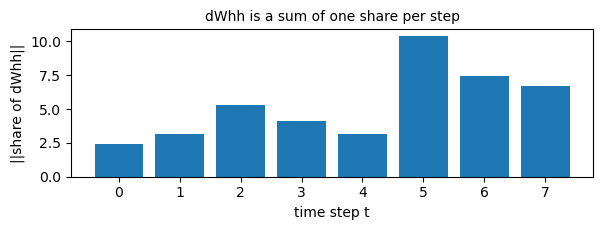

In [3]:
def rnn_forward(X, h0, Wxh, Whh, bh):
    H, h = np.empty((X.shape[0],) + h0.shape), h0
    for t in range(X.shape[0]):
        h = np.tanh(X[t] @ Wxh + h @ Whh + bh)
        H[t] = h
    return H

def bptt(X, h0, H, Wxh, Whh, dH):
    dWxh, dWhh, dbh = np.zeros_like(Wxh), np.zeros_like(Whh), np.zeros(Whh.shape[0])
    dh_next, share = np.zeros_like(h0), []
    for t in reversed(range(X.shape[0])):
        dh = dH[t] + dh_next                     # from the output at t, and from step t+1
        dz = dh * (1.0 - H[t] ** 2)              # back through tanh
        h_prev = H[t - 1] if t > 0 else h0
        dWxh += X[t].T @ dz                      # every step adds its share...
        dWhh += h_prev.T @ dz
        dbh += dz.sum(axis=0)
        share.append(np.linalg.norm(h_prev.T @ dz))
        dh_next = dz @ Whh.T                     # ...and passes the rest one step back
    return dWxh, dWhh, dbh, dh_next, share[::-1]

rng = np.random.default_rng(0)
T, m, n_in, n_h = 8, 3, 4, 5
Xg, h0 = rng.standard_normal((T, m, n_in)), rng.standard_normal((m, n_h)) * 0.5
P = [rng.standard_normal(s) * 0.6 for s in ((n_in, n_h), (n_h, n_h), (n_h,))]
G = rng.standard_normal((T, m, n_h))             # L = sum(H * G), so dL/dH = G
H = rnn_forward(Xg, h0, *P)
grads = bptt(Xg, h0, H, P[0], P[1], G)
loss = lambda _: float((rnn_forward(Xg, h0, *P) * G).sum())
for name, p, g in zip(('dWxh', 'dWhh', 'dbh'), P, grads):
    err = rel_error(g, eval_numerical_gradient(loss, p))
    print(f'{name} vs finite differences: rel_error = {err:.1e}'); assert err < 1e-7
err = rel_error(grads[3], eval_numerical_gradient(lambda _: float((rnn_forward(Xg, h0, *P) * G).sum()), h0))
print(f'dh0  vs finite differences: rel_error = {err:.1e}'); assert err < 1e-7

lay = ng.RNN(n_in, n_h); lay.Wxh[:], lay.Whh[:], lay.bh[:] = P
lay.forward(Xg, h0); lay.backward(G)
assert max(rel_error(a, b) for a, b in zip(lay.grads(), grads[:3])) < 1e-12
print('nanograd.RNN computes the same gradients')

fig, ax = plt.subplots(figsize=(6, 2.4))
ax.bar(range(T), grads[4], color='tab:blue')
ax.set_xlabel('time step t'); ax.set_ylabel('||share of dWhh||')
ax.set_title('dWhh is a sum of one share per step', fontsize=10)
plt.tight_layout(); plt.show()

## 3. The echo toy, and Elman's training

The first toy isolates memory. A stream of symbols from a four-letter alphabet `A B C D`, drawn
at random; at every step the target is the symbol read **$d$ steps earlier** (no target for the
first $d$ steps). There is nothing to infer — the network just has to hold the last $d$
symbols in its 16 hidden units and hand each one over when its time comes: a shift register
built from tanh units. Every update draws a fresh batch of 32 sequences of 24 steps, so it cannot
memorize; it is tested on sequences of 96.

We train it twice, from the same initial weights on the same batches. The **BPTT** twin gets the
full gradient through time. The **Elman** twin gets Elman's 1990 training: the previous state
$h^{\langle t-1\rangle}$ is treated as just another input, and the gradient stops there —
`RNN.backward(dH, truncate=1)`. Their forward passes are identical, so both networks *carry*
information from step to step. The only difference is whether the training signal can say what
to carry.

(1s)
BPTT              : final batch loss 0.0071   test accuracy (96-step sequences) 1.000
Elman (truncate=1): final batch loss 1.1882   test accuracy (96-step sequences) 0.465


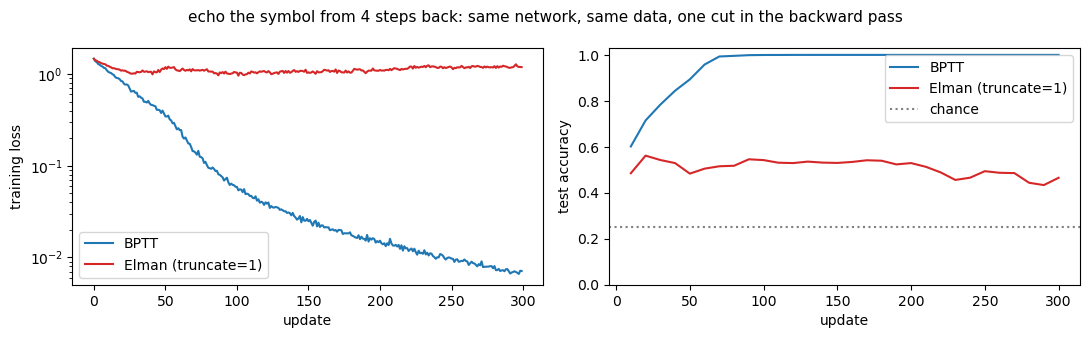


        0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9
input   B C D D A A D D A B D B B D B B C C A A D D D C D B B D A B
target          B C D D A A D D A B D B B D B B C C A A D D D C D B
BPTT            B C D D A A D D A B D B B D B B C C A A D D D C D B
Elman           D D C B A A D D A B A D B B C C C B A A A D C C D A


In [4]:
t0 = time.time()
twins = {k: canon.train_echo(delay=canon.DELAY, truncate=k, record_every=10) for k in (0, 1)}
print(f'({time.time() - t0:.0f}s)')
names = {0: 'BPTT', 1: 'Elman (truncate=1)'}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for k, c in ((0, 'tab:blue'), (1, 'tab:red')):
    axes[0].plot(twins[k]['loss'], c=c, label=names[k])
    s, a = zip(*twins[k]['curve'])
    axes[1].plot(s, a, c=c, label=names[k])
    print(f"{names[k]:18s}: final batch loss {twins[k]['loss'][-1]:.4f}   test accuracy (96-step sequences) {twins[k]['acc']:.3f}")
axes[0].set_yscale('log'); axes[0].set_xlabel('update'); axes[0].set_ylabel('training loss'); axes[0].legend()
axes[1].axhline(0.25, ls=':', c='grey', label='chance'); axes[1].set_ylim(0, 1.03)
axes[1].set_xlabel('update'); axes[1].set_ylabel('test accuracy'); axes[1].legend()
fig.suptitle(f'echo the symbol from {canon.DELAY} steps back: same network, same data, one cut in the backward pass', fontsize=11)
plt.tight_layout(); plt.show()

S = np.random.default_rng(1).integers(0, 4, size=(30, 1))
print('\n        ' + ' '.join(f'{t % 10}' for t in range(30)))
print('input   ' + ' '.join(SYM[s] for s in S[:, 0]))
print('target  ' + '  ' * canon.DELAY + ' '.join(SYM[s] for s in S[:-canon.DELAY, 0]))
for k in (0, 1):
    Hk = twins[k]['rnn'].forward(canon.one_hot(S))
    pred = twins[k]['head'].forward(Hk[canon.DELAY:, 0]).argmax(1)
    print(f"{'BPTT' if k == 0 else 'Elman':8s}" + '  ' * canon.DELAY + ' '.join(SYM[p] for p in pred))
assert twins[0]['acc'] == 1.0 and twins[1]['acc'] < 0.6

The BPTT twin is perfect within about 125 updates, on sequences four times longer than any it
trained on — the same weights do the same thing at every step, so a rule learned on 24 steps
holds on 96. The Elman twin never gets there: its loss falls a little and then *rises* again, and
its accuracy peaks near 54% and slides back to 47%. That is better than the 25% of guessing —
even an untrained recurrence leaves traces of the last few symbols in the state, and the read-out
can learn to use some of them — but it is not a memory. Its forward pass is the BPTT twin's
exactly. What it lacks is the gradient that would teach $W_{xh}$ and $W_{hh}$ to *keep*
the symbol for four steps, and keep it in a form the read-out can use, has to travel back four
steps to get there — and Elman's training cuts it after one. Even a one-step echo fails this
way (§4). That is not the end of Elman's method: §6 finds a task it learns perfectly, and the
difference between the two tasks is the lesson of this module.

## 4. How far back can it remember?

Two sweeps. First, **truncation**: cut the gradient's path into the past every $k$ steps —
`truncate=k`, exactly what happens when a long text is trained in chunks of $k$ steps with the
state carried across (the test suite checks that equivalence to $10^{-15}$) — and ask which
delays $d$ each $k$ can learn. $k = 1$ is Elman's training; $k = \infty$ is full BPTT.

(30s)


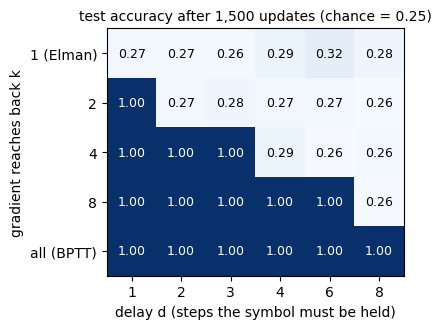

learned (> 95%) exactly when d < k: the network learns to remember only as far back as the gradient reaches


In [5]:
KS, DS = (1, 2, 4, 8, 0), (1, 2, 3, 4, 6, 8)        # truncate=0 means never: full BPTT
t0 = time.time()
reach = np.array([[canon.train_echo(delay=d, truncate=k, steps=1500)['acc'] for d in DS] for k in KS])
print(f'({time.time() - t0:.0f}s)')
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.imshow(reach, cmap='Blues', vmin=0.25, vmax=1.0)
for i in range(len(KS)):
    for j in range(len(DS)):
        ax.text(j, i, f'{reach[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if reach[i, j] > 0.7 else 'black')
ax.set_xticks(range(len(DS)), DS); ax.set_xlabel('delay d (steps the symbol must be held)')
ax.set_yticks(range(len(KS)), ['1 (Elman)', '2', '4', '8', 'all (BPTT)']); ax.set_ylabel('gradient reaches back k')
ax.set_title('test accuracy after 1,500 updates (chance = 0.25)', fontsize=10)
plt.tight_layout(); plt.show()
for i, k in enumerate(KS):
    for j, d in enumerate(DS):
        assert (reach[i, j] > 0.95) == (k == 0 or d < k), (k, d, reach[i, j])
print('learned (> 95%) exactly when d < k: the network learns to remember only as far back as the gradient reaches')

The table is a staircase. With the gradient cut every $k$ steps the network learns every delay
shorter than $k$ — perfectly — and *none* of the others, not even partially. Nothing else limits
it: the forward pass, the data and the budget are the same in every cell. A recurrent network
learns to remember only as far back as its training gradient reaches.

So with full backpropagation through time, is there any limit? The second sweep trains on
longer sequences ($T = 2d + 16$) for 3,000 updates, two seeds per delay.

(47s)
16 units: d=4: 1.000  d=8: 1.000  d=12: 0.996  d=16: 0.838  d=20: 0.588  d=24: 0.249  d=32: 0.251


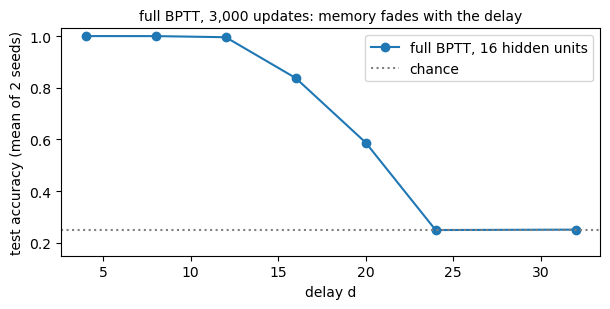

In [6]:
DELAYS = (4, 8, 12, 16, 20, 24, 32)
t0 = time.time()
delay_acc = np.array([[canon.train_echo(delay=d, steps=3000, T=2 * d + 16, seed=s)['acc']
                       for s in range(2)] for d in DELAYS])
print(f'({time.time() - t0:.0f}s)')
print('16 units: ' + '  '.join(f'd={d}: {a.mean():.3f}' for d, a in zip(DELAYS, delay_acc)))
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(DELAYS, delay_acc.mean(1), 'o-', c='tab:blue', label='full BPTT, 16 hidden units')
ax.axhline(0.25, ls=':', c='grey', label='chance')
ax.set_xlabel('delay d'); ax.set_ylabel('test accuracy (mean of 2 seeds)'); ax.set_ylim(0.15, 1.03); ax.legend()
ax.set_title('full BPTT, 3,000 updates: memory fades with the delay', fontsize=10)
plt.tight_layout(); plt.show()
acc_by_d = dict(zip(DELAYS, delay_acc.mean(1)))
assert min(acc_by_d[d] for d in (4, 8, 12)) > 0.95 and max(acc_by_d[d] for d in (24, 32)) < 0.35

Sixteen units hold a symbol perfectly for eight steps and almost perfectly for twelve; at sixteen
steps they get about 84% right, at twenty under 60%, and from twenty-four on nothing at all. Some of
that ceiling may be capacity — twenty two-bit symbols is a lot to keep in sixteen tanh units — but
the staircase has already shown that the gradient's reach alone is enough to impose a limit. The
next section measures how fast that reach runs out even when nothing truncates it.

## 5. Why: the gradient through time

Follow one gradient back from the last step. Each step multiplies it by the same kind of matrix:

$$\frac{\partial L}{\partial h^{\langle t-k\rangle}} = \frac{\partial L}{\partial h^{\langle t\rangle}}
\prod_{j=0}^{k-1} \mathrm{diag}\big(1 - (h^{\langle t-j\rangle})^2\big)\, W_{hh}^{\top}.$$

A deep feed-forward network multiplies *different* Jacobians, one per layer (Module 05). A
recurrent network multiplies *the same* $W_{hh}^{\top}$ over and over, so the gradient behaves
like a power of a matrix: it shrinks geometrically if $W_{hh}$'s largest eigenvalue magnitude —
its **spectral radius** $\rho$ — is below 1, and can grow geometrically above it (the tanh
derivatives, all $\le 1$, only shrink it further). Sepp Hochreiter worked this out in his 1991
diploma thesis; Bengio, Simard and Frasconi (1994) proved that it is not an accident of
initialization: a network that stores a bit *robustly* — immune to small noise — is exactly one
whose gradients from the far past vanish.

Measure it: send a unit gradient into the last hidden state of a 40-step sequence and record how
much arrives at each earlier step, for $W_{hh}$ drawn with Xavier's $\mathrm{std} = 1/\sqrt{n_h}$
and then scaled by a gain. (Xavier's scale is not arbitrary here: by the *circular law*, the
eigenvalues of an $n \times n$ matrix of independent entries with variance $1/n$ fill the unit
disc, so Xavier puts the spectral radius at about 1 — the edge between vanishing and exploding.)

gain 0.5: rho = 0.52;  gradient 10 steps back 1.19e-04, 39 steps back 9.16e-16
gain 1.0: rho = 1.03;  gradient 10 steps back 6.45e-02, 39 steps back 1.93e-05
gain 1.5: rho = 1.55;  gradient 10 steps back 7.57e-01, 39 steps back 4.27e-01
gain 2.0: rho = 2.06;  gradient 10 steps back 2.06e+00, 39 steps back 5.05e+01
gain 3.0: rho = 3.10;  gradient 10 steps back 7.98e+00, 39 steps back 1.37e+04


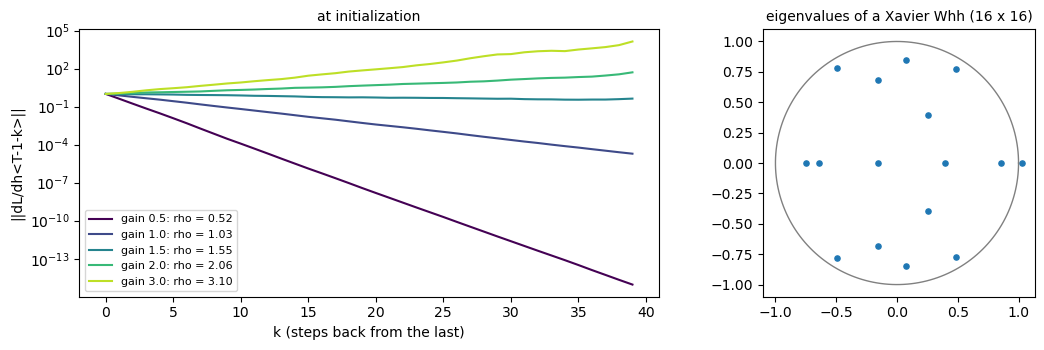

In [7]:
GAINS = (0.5, 1.0, 1.5, 2.0, 3.0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
gtt_init = {}
for g, c in zip(GAINS, plt.cm.viridis(np.linspace(0, 0.9, len(GAINS)))):
    net, _ = canon.build_echo_net(gain=g)
    gtt_init[g] = canon.grad_through_time(net)
    axes[0].semilogy(gtt_init[g], c=c, label=f'gain {g}: rho = {canon.spectral_radius(net.Whh):.2f}')
    print(f'gain {g}: rho = {canon.spectral_radius(net.Whh):.2f};  gradient 10 steps back {gtt_init[g][10]:.2e}, '
          f'39 steps back {gtt_init[g][39]:.2e}')
axes[0].set_xlabel('k (steps back from the last)'); axes[0].set_ylabel('||dL/dh<T-1-k>||'); axes[0].legend(fontsize=8)
axes[0].set_title('at initialization', fontsize=10)
net, _ = canon.build_echo_net()
ev = np.linalg.eigvals(net.Whh)
axes[1].scatter(ev.real, ev.imag, s=14, c='tab:blue'); th = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(np.cos(th), np.sin(th), c='grey', lw=1); axes[1].set_aspect('equal')
axes[1].set_title('eigenvalues of a Xavier Whh (16 x 16)', fontsize=10)
plt.tight_layout(); plt.show()
assert gtt_init[0.5][10] < 1e-3 and gtt_init[3.0][39] > 1e3

At gain 0.5 the gradient is down to $10^{-4}$ ten steps back and to rounding error by forty; at
Xavier's own scale it still falls about tenfold every eight steps. Above $\rho \approx 1.5$ it
*grows* with distance — at gain 3, more than ten thousand times over forty steps. No single scale
makes $\rho^k$ stay near 1 for every $k$. At the start of training, then, a 24-step dependency
sends back a signal a few thousandths the size of a 4-step one, buried under the larger gradients
of everything nearer — which is why long delays are learned late or not at all (§4).
Training does reshape the profile — here is the same measurement on trained networks.

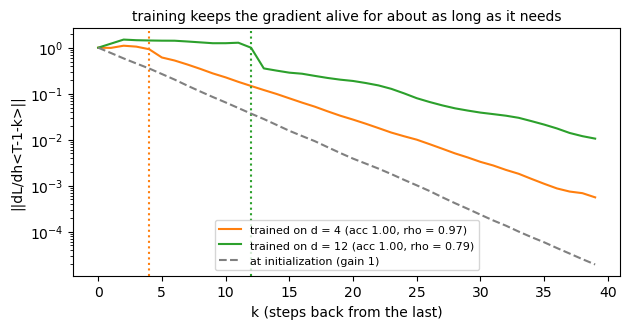

gradient 12 steps back: at init 0.037, trained on d=4 0.147, trained on d=12 0.998


In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
gtt_trained = {}
for d, c in ((4, 'tab:orange'), (12, 'tab:green')):
    res = canon.train_echo(delay=d, steps=3000 if d > 4 else canon.TOY_STEPS, T=2 * d + 16 if d > 4 else canon.T_TOY)
    gtt_trained[d] = canon.grad_through_time(res['rnn'])
    ax.semilogy(gtt_trained[d], c=c, label=f"trained on d = {d} (acc {res['acc']:.2f}, rho = {canon.spectral_radius(res['rnn'].Whh):.2f})")
    ax.axvline(d, c=c, ls=':')
ax.semilogy(gtt_init[1.0], c='grey', ls='--', label='at initialization (gain 1)')
ax.set_xlabel('k (steps back from the last)'); ax.set_ylabel('||dL/dh<T-1-k>||'); ax.legend(fontsize=8)
ax.set_title('training keeps the gradient alive for about as long as it needs', fontsize=10)
plt.tight_layout(); plt.show()
print(f'gradient 12 steps back: at init {gtt_init[1.0][12]:.3f}, trained on d=4 {gtt_trained[4][12]:.3f}, '
      f'trained on d=12 {gtt_trained[12][12]:.3f}')
assert gtt_trained[12][12] > 5 * gtt_init[1.0][12]

The network trained on a 12-step delay holds its gradient near 1 for about twelve steps and then
lets it fall; the one trained on 4 steps keeps it somewhat longer than initialization did. Each
learned to keep the gradient alive roughly as long as its task needed — but only as far as it
could already see, which is the trap: to *learn* that a dependency spans 30 steps, the gradient
must already carry something useful 30 steps back.

### Exploding gradients: the cliff, and clipping

The other half is rarer but more violent. Pascanu, Mikolov and Bengio (2013) drew it with a
recurrent network of **one** unit, small enough to plot its entire loss surface. Ours:
$h^{\langle t\rangle} = \tanh(w\, h^{\langle t-1\rangle} + b)$, started at $h^{\langle 0\rangle} = 0.5$,
run for 50 steps, with loss $\tfrac12 (h^{\langle 50\rangle} + 0.5)^2$. For $w > 1$ the map has
two stable fixed points, one positive and one negative; which one the state ends at depends on
$(w, b)$, and where the answer flips, the final state jumps. In the loss surface that is a
**cliff**: a ridge across which the loss changes abruptly, with gradients hundreds of times larger
than almost anywhere else.

Gradient descent that lands on the cliff takes one enormous step and is thrown far across the
surface. **Gradient-norm clipping** — if $\|g\| > \tau$, rescale $g \leftarrow \tau g / \|g\|$ —
keeps the direction and caps the length, so the cliff costs one ordinary step. The code uses the
`RNN` layer itself, with one input (always zero) and one hidden unit, and the library's
`clip_grad_norm`.

no clipping : ends at (w, b) = (-9.05, -25.02), loss 0.125, largest step 27
clipped at 1: ends at (w, b) = (0.98, -0.06), loss 1.34e-09, largest step 0.2


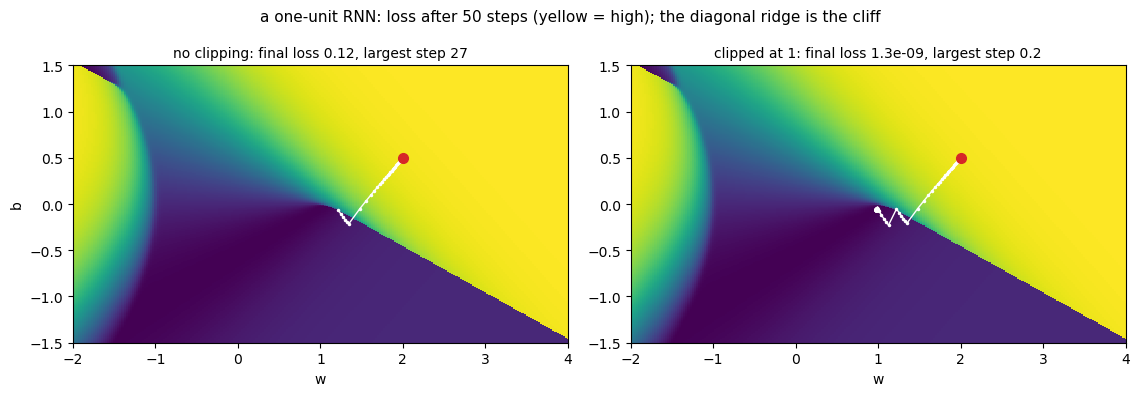

In [9]:
T_CLIFF, H0, TARGET = 50, 0.5, -0.5

def cliff_loss_grad(w, b):
    lay = ng.RNN(1, 1); lay.Whh[0, 0], lay.bh[0] = w, b
    H = lay.forward(np.zeros((T_CLIFF, 1, 1)), np.full((1, 1), H0))
    e = H[-1, 0, 0] - TARGET
    dH = np.zeros_like(H); dH[-1, 0, 0] = e
    lay.backward(dH)
    return 0.5 * e * e, np.array([lay.dWhh[0, 0], lay.dbh[0]])

ws, bs = np.linspace(-2, 4, 241), np.linspace(-1.5, 1.5, 241)
Wg, Bg = np.meshgrid(ws, bs)
hg = np.full_like(Wg, H0)
for _ in range(T_CLIFF):                 # the same recurrence, vectorized over the whole grid
    hg = np.tanh(Wg * hg + Bg)
L_grid = 0.5 * (hg - TARGET) ** 2

def descend(start, lr=0.2, steps=300, clip=None):
    p, path = np.array(start, dtype=float), [start]
    for _ in range(steps):
        loss, g = cliff_loss_grad(*p)
        if clip is not None:
            ng.clip_grad_norm([g], clip)
        p = p - lr * g
        path.append(tuple(p))
    return np.array(path), loss

paths = {clip: descend((2.0, 0.5), clip=clip) for clip in (None, 1.0)}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, clip in zip(axes, (None, 1.0)):
    ax.pcolormesh(ws, bs, L_grid, shading='auto', cmap='viridis')
    path, loss = paths[clip]
    inside = (path[:, 0] > ws[0]) & (path[:, 0] < ws[-1]) & (path[:, 1] > bs[0]) & (path[:, 1] < bs[-1])
    ax.plot(path[inside, 0], path[inside, 1], '.-', c='white', ms=3, lw=1)
    ax.plot(*path[0], 'o', c='tab:red', ms=7)
    jump = np.linalg.norm(np.diff(path, axis=0), axis=1)
    label = 'no clipping' if clip is None else 'clipped at 1'
    ax.set_title(f'{label}: final loss {loss:.2g}, largest step {jump.max():.3g}', fontsize=10)
    ax.set_xlabel('w'); ax.set_xlim(ws[0], ws[-1]); ax.set_ylim(bs[0], bs[-1])
    print(f'{label:12s}: ends at (w, b) = ({path[-1, 0]:.2f}, {path[-1, 1]:.2f}), loss {loss:.3g}, '
          f'largest step {jump.max():.3g}')
axes[0].set_ylabel('b')
fig.suptitle('a one-unit RNN: loss after 50 steps (yellow = high); the diagonal ridge is the cliff', fontsize=11)
plt.tight_layout(); plt.show()
assert paths[1.0][1] < 1e-6 < paths[None][1]

Both runs start at the red dot and walk the same way at first. The unclipped one reaches the
ridge, receives a gradient a few hundred times larger than the steps before, and is flung out of
the picture to a region where the state is pinned at a fixed point, the gradient is almost zero
and the loss is stuck. The clipped one crosses the same ridge in steps no longer than 0.2 and
walks down to a loss below $10^{-6}$. Clipping is not an optimizer and does nothing on ordinary
steps; it is insurance against the rare one. (On this module's other runs — the echo toy with
Adam, the Shakespeare model — the clip never fires: Adam already divides each step by a running
size of the gradient. With plain SGD on long sequences it is often the difference between
training and not, which is why it became standard.)

## 6. Counting: a state machine that runs forever

The second toy asks for something that sounds harder. The input is a stream of random bits, and
the target at every step is **how many 1s have arrived so far, mod 3**. The answer depends on the
*entire* history — but only through one of three values, updated by a fixed rule: a 1 advances
the count, a 0 leaves it. A finite-state machine with three states in a cycle.

Train on streams of 20 bits; test on streams of 20, 1,000 and 10,000. And train it twice: with
full BPTT, and with Elman's one-step truncation, which could not learn even a one-step echo.

(2s)


BPTT : final loss 0.00043;  accuracy on streams of 20 bits: 1.0000, 1,000 bits: 1.0000, 10,000 bits: 1.0000
Elman: final loss 0.00091;  accuracy on streams of 20 bits: 1.0000, 1,000 bits: 1.0000, 10,000 bits: 1.0000


variance of the hidden state NOT explained by count                 : 72.9%
variance of the hidden state NOT explained by count + current bit   : 26.3%
variance of the hidden state NOT explained by count + last two bits : 3.2%


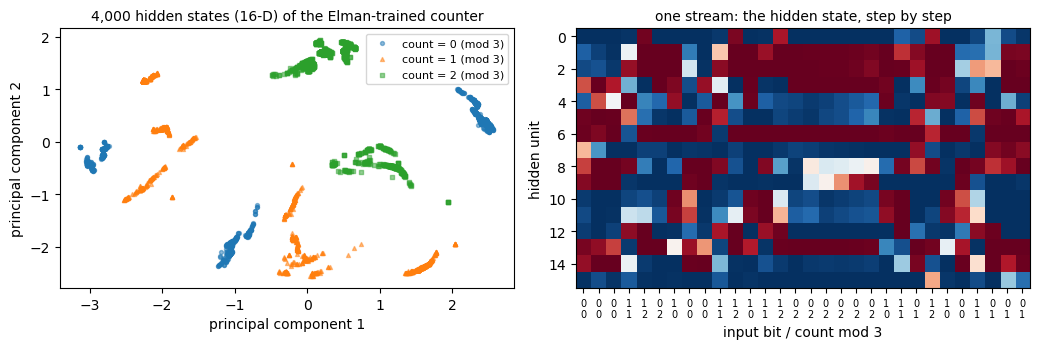

In [10]:
t0 = time.time()
count_runs = {k: canon.train_counting(truncate=k) for k in (0, 1)}
print(f'({time.time() - t0:.0f}s)')
count_acc = {}
for k in (0, 1):
    count_acc[k] = {T: canon.counting_accuracy(count_runs[k]['rnn'], count_runs[k]['head'], T, m=50)[0]
                    for T in (20, 1000, 10000)}
    print(f"{'BPTT ' if k == 0 else 'Elman'}: final loss {count_runs[k]['loss'][-1]:.5f};  accuracy on streams of "
          + ', '.join(f'{T:,} bits: {a:.4f}' for T, a in count_acc[k].items()))
    assert count_acc[k][10000] > 0.999

acc, Hc, yc = canon.counting_accuracy(count_runs[1]['rnn'], count_runs[1]['head'], 200, m=20)
pts = Hc.reshape(-1, Hc.shape[2])
# What does the state record? The fraction of its variance left unexplained when states are
# grouped by the count alone, by (count, current bit), and by (count, current bit, previous bit).
bits = canon.counting_batch(np.random.default_rng(40_000), 20, 200)[0][:, :, 1].astype(int)
prev = np.concatenate([np.zeros((1, 20), int), bits[:-1]])
def unexplained(*keys):
    lab = np.stack([k.reshape(-1) for k in keys], axis=1)
    tot = sum(((pts[(lab == u).all(1)] - pts[(lab == u).all(1)].mean(0)) ** 2).sum() for u in np.unique(lab, axis=0))
    return tot / ((pts - pts.mean(0)) ** 2).sum()
for name, keys in (('count', (yc,)), ('count + current bit', (yc, bits)), ('count + last two bits', (yc, bits, prev))):
    print(f'variance of the hidden state NOT explained by {name:22s}: {unexplained(*keys):.1%}')
assert unexplained(yc, bits, prev) < 0.1
_, _, vt = np.linalg.svd(pts - pts.mean(0), full_matrices=False)
proj = (pts - pts.mean(0)) @ vt[:2].T
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for c, mk, col in zip(range(3), 'o^s', ('tab:blue', 'tab:orange', 'tab:green')):
    sel = yc.reshape(-1) == c
    axes[0].scatter(proj[sel, 0], proj[sel, 1], s=8, marker=mk, c=col, alpha=0.5, label=f'count = {c} (mod 3)')
axes[0].set_xlabel('principal component 1'); axes[0].set_ylabel('principal component 2'); axes[0].legend(fontsize=8)
axes[0].set_title('4,000 hidden states (16-D) of the Elman-trained counter', fontsize=10)
X1b, y1b = canon.counting_batch(np.random.default_rng(7), 1, 30)
H1b = count_runs[1]['rnn'].forward(X1b)[:, 0]
axes[1].imshow(H1b.T, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
axes[1].set_xticks(range(30), [f'{int(b)}\n{c}' for b, c in zip(X1b[:, 0, 1], y1b[:, 0])], fontsize=7)
axes[1].set_xlabel('input bit / count mod 3'); axes[1].set_ylabel('hidden unit')
axes[1].set_title('one stream: the hidden state, step by step', fontsize=10)
plt.tight_layout(); plt.show()

Both networks count perfectly — on streams five hundred times longer than they trained on — and
the Elman-trained one is as good as the other. Its hidden states fall into tight, separate
clusters, and every cluster belongs to exactly one count, so the read-out only has to say which
cluster the state is in. But it did not build the minimal three-state machine. There are about a
dozen clusters, and the variance analysis says what they are: the count *and the last two bits
read* — twelve combinations that account for over 95% of the state's variance, where the count
alone accounts for about a quarter. The network built a larger finite-state machine than it needed,
each of its states tagged with one count, out of tanh units, as **attractors** of its dynamics —
which is why it never drifts however long it runs. (Nothing asked it to be minimal; remembering the
last bits costs it nothing.)

So why can Elman's training learn to count but not to echo a symbol one step back? Look at what
the gradient has to do. In the counter, **every step's target is the state itself**: the loss at
step $t$ says directly "your state should mean *count = 2* now", and a one-step gradient can teach
the update rule — *state, bit → next state* — one step at a time. In the echo, what the network
must keep — the symbol it just read — is **not what it is asked for now**; it is asked for $d$
steps later, and only a gradient that travels back $d$ steps can say "you should have kept that".
What a recurrent network can learn depends less on how long its sequences are than on how far
apart a piece of information and the moment it is needed are, compared with how far back its
gradient reaches. Stretching that distance is what Module 07's LSTM was built for.

Elman's own experiments were next-item prediction, where much of what must be remembered is
also visible in the targets along the way — which is why his truncated training got as far as it
did.

## 7. Verify against the canonical `rnn.py` and the C mirror

`ToyRNN` trains both echo twins with every sum in `lib/c/nanograd`'s loop order, from the same LCG
streams as `c/rnn.c`, and with the C library's own `tanh`, `exp` and `log` (Python's `math`
module; NumPy's `tanh` differs from it in the last bit for about a fifth of all inputs).
`tests/test_agreement.py` compiles the C and asserts both twins' fingerprints match.

In [11]:
t0 = time.time()
fp = {k: dict(canon.run_toy(truncate=k)) for k in (0, 1)}
print(f"{'':11s}{'BPTT':>24s}{'Elman':>24s}   ({time.time() - t0:.0f}s of C-order NumPy)")
for key in fp[0]:
    print(f'{key:11s}{fp[0][key]:24.15g}{fp[1][key]:24.15g}')
assert fp[0]['acc'] == 1.0 and fp[1]['acc'] < 0.6
print('OK: the BPTT twin echoes perfectly, the Elman twin cannot; c/rnn.c prints the same digits '
      '(see tests/test_agreement.py)')

                               BPTT                   Elman   (3s of C-order NumPy)
loss            0.00655944328597496        1.24243356085951
acc                               1               0.4296875
batch_loss      0.00699789762926032        1.23531495598888
gnorm            0.0500225839076084       0.129818212255422
n_clip                            0                       0
wsum               2.01642733948393       -1.81374835261619
wxh_00           -0.512766892812121       -0.70340659255518
whh_00            0.269628721985165       0.195983790259938
why_00            0.303432205239605      -0.147147542722399
OK: the BPTT twin echoes perfectly, the Elman twin cannot; c/rnn.c prints the same digits (see tests/test_agreement.py)


## 8. Tiny Shakespeare: a character-level language model

The real task is the one that made recurrent networks famous in 2015, when Andrej Karpathy
published *The Unreasonable Effectiveness of Recurrent Neural Networks* and the code behind it:
read text one character at a time and, at every step, predict the next character. The data is
his **Tiny Shakespeare** — about 40,000 lines of the plays in one 1.1-million-character file,
speaker names and all, 65 distinct characters. The first 90% trains; the last 10%, passages the
model never sees, validates.

The loss is the one we have used since Module 01: the mean negative log-probability the model
gave the character that actually came next, in **nats per character** (divide by $\ln 2$ for
bits). Guessing uniformly among 65 characters scores $\ln 65 = 4.17$. The honest baselines are
**n-gram** models, which predict each character by counting what followed the same $n-1$
characters in the training text (with add-$\alpha$ smoothing, $\alpha$ chosen on the validation
text to flatter them).

In [12]:
data = canon.load_text_data()
train_ids, val_ids, chars = data
V_CH = len(chars)
print(f'{V_CH} characters: {"".join(chars)!r}')
print(f'train {train_ids.size:,} characters, validation {val_ids.size:,}')
print('-' * 60); print(''.join(chars[i] for i in val_ids[:300])); print('-' * 60)
t0 = time.time()
ngram = canon.ngram_losses(train_ids, val_ids, V_CH, orders=(1, 2, 3, 4, 5, 6, 7))
print(f'n-gram baselines ({time.time() - t0:.0f}s), validation loss in nats/char:')
print(f'  uniform over 65: {math.log(V_CH):.4f}')
for n, (loss, a) in ngram.items():
    print(f'  order {n} (context of {n - 1}): {loss:.4f}   (alpha = {a})')
best_ngram = min(loss for loss, _ in ngram.values())
assert best_ngram < 1.8

65 characters: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
train 1,003,854 characters, validation 111,540
------------------------------------------------------------
?

GREMIO:
Good morrow, neighbour Baptista.

BAPTISTA:
Good morrow, neighbour Gremio.
God save you, gentlemen!

PETRUCHIO:
And you, good sir! Pray, have you not a daughter
Call'd Katharina, fair and virtuous?

BAPTISTA:
I have a daughter, sir, called Katharina.

GREMIO:
You are too blunt: go to it o
------------------------------------------------------------


n-gram baselines (0s), validation loss in nats/char:
  uniform over 65: 4.1744
  order 1 (context of 0): 3.3473   (alpha = 0.01)
  order 2 (context of 1): 2.4819   (alpha = 1.0)
  order 3 (context of 2): 2.0458   (alpha = 0.1)
  order 4 (context of 3): 1.7793   (alpha = 0.03)
  order 5 (context of 4): 1.7503   (alpha = 0.03)
  order 6 (context of 5): 1.9790   (alpha = 0.03)
  order 7 (context of 6): 2.3419   (alpha = 0.03)


Counting works surprisingly well up to a point: each extra character of context cuts the loss,
down to about 1.75 nats with four characters of context. Then it turns around. Most 6- and
7-character contexts in the validation text occur rarely or never in training, so their counts are
too thin to trust and the model falls back on smoothing. A table of counts cannot generalize from
"the king" to "the queen"; every context is learned separately.

The recurrent network conditions on *everything* it has read, through a 256-number state, and
shares what it learns across contexts. The training text is cut into 64 parallel streams; each
update reads the next 64 characters of every stream, and the state carries from one update to the
next — so the network's memory reaches back as far as the stream goes, while its gradient
reaches back at most 64 characters (truncated BPTT, as in §4). Adam, gradient norm clipped at 5,
float32, twenty epochs with the learning rate halved twice near the end. The run is cached: the
first time it takes about ten minutes of NumPy.

[char] loaded checkpoint 8b707dcab71d (20 epochs, val_loss=1.6535)
RNN(65 -> 256) + Linear: 99,137 parameters; validation loss 1.6535 nats/char (2.386 bits) vs the best n-gram 1.7503
gradient clipped on 0.0% of updates at most, in any epoch


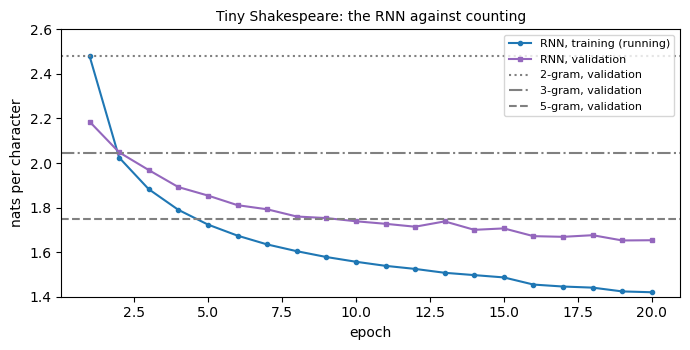

In [13]:
model, val_loss, hist = canon.run_char(data=data, cache=True, verbose=True)
n_par = sum(p.size for p in model.params())
print(f'RNN(65 -> {canon.CHAR_H}) + Linear: {n_par:,} parameters; validation loss {val_loss:.4f} nats/char '
      f'({val_loss / math.log(2):.3f} bits) vs the best n-gram {best_ngram:.4f}')
print(f"gradient clipped on {max(h['clipped'] for h in hist):.1%} of updates at most, in any epoch")
fig, ax = plt.subplots(figsize=(7, 3.6))
ep = np.arange(1, len(hist) + 1)
ax.plot(ep, [h['train_loss'] for h in hist], 'o-', c='tab:blue', ms=3, label='RNN, training (running)')
ax.plot(ep, [h['val_loss'] for h in hist], 's-', c='tab:purple', ms=3, label='RNN, validation')
for n, ls in ((2, ':'), (3, '-.'), (5, '--')):
    ax.axhline(ngram[n][0], c='grey', ls=ls, label=f'{n}-gram, validation')
ax.set_xlabel('epoch'); ax.set_ylabel('nats per character'); ax.set_ylim(1.4, 2.6); ax.legend(fontsize=8)
ax.set_title('Tiny Shakespeare: the RNN against counting', fontsize=10)
plt.tight_layout(); plt.show()
assert val_loss <= canon.CHAR_TARGET and val_loss < best_ngram

### What it writes

After each epoch the training loop asked the model to continue `ROMEO:` for 300 characters,
sampling each next character from its own predicted distribution (temperature 0.8, the same
random seed every time). Watching those samples is the clearest way to see what a language model
learns, and in what order.

In [14]:
for e in (0, 2, 9, len(hist) - 1):
    print(f"==== after epoch {e + 1} (validation loss {hist[e]['val_loss']:.3f}) ====")
    print(hist[e]['sample'][:300]); print()

==== after epoch 1 (validation loss 2.186) ====
ROMEO:
Se art pith tas the ain thyour'd sillly of her math the him le peofre stes ints ringeres out ttretot ersande th taser the willd and the sithema-foit tak om thid heve fot hy buthoure cos is mane wians fer mit ou has horeis aflind,
Then serew, the ouck fwimed rover hen m poisstonto, thou soch m

==== after epoch 3 (validation loss 1.969) ====
ROMEO:
Sha tringer
Wathing Jornedy?

LEDWARD:
He reas netero'd my blace,
As anr wherture, shell out
Wouck.

CORIOLBEUS:
'llo san, in the lither.
The seever tald!
To the hus cruncuness, with precour nocre
To have oul see then with arf and in and iveseer.
O they of Herrence,
An the rustry, whor that i

==== after epoch 10 (validation loss 1.739) ====
ROMEO:
Placks of tay this in the wring and my heart the state and all
Which bequireds, sir; strangs to driph to sholl I am thine villoe his king.

KING RICHARD III:
We may canst your mustice, and the bus
To have my heart,
Is thre do not so said, your 

The order is the one Karpathy described: first the statistics of characters — spaces at about the
right rate, common letters — then words, then the *form* of the text: a speaker's name in capitals,
a colon, a line break, lines of verse of about the right length, the punctuation of dialogue. The
words become mostly real and the phrases sometimes are; the meaning never arrives. 256 numbers of
state are enough to know that it is in the middle of a speech and roughly what a line of
Shakespeare looks like, not what anyone is talking about.

**Temperature** divides the logits before the softmax: below 1 it sharpens the distribution toward
the likeliest characters, above 1 it flattens it.

In [15]:
for temp in (0.3, 0.8, 1.2):
    print(f'==== temperature {temp} ====')
    print(model.sample(chars, n=250, temperature=temp, seed=1)); print()

==== temperature 0.3 ====
ROMEO:
How now the house of his rester thee that make her sense the brother, and the world think of bearth the world shall be some him and the sun be deneration,
When I will say it is to the better than the since the duke of him.

CORIOLANUS:
The fair bear 

==== temperature 0.8 ====


ROMEO:
Is the heavenering gracious dumberer kill, and this comest; about his desirest.

First Citizen:
And thou hast danger is strange in suep.
Now in the may bold have not it with him! O, examuners he live.

Nurse:
Give me his unforce a master, I have eart

==== temperature 1.2 ====
ROMEO:
It well lave upon his iture by anstuble
To exils profom-sour 'twom out norcaly. Should be raibed men,
Who lay dasted is not in changry: lord hands that ever havenched why,
Theich; they eyes them find me; sir, betised by by men caljedly.
To Richard so



At 0.3 the model plays it safe and loops on its favourite phrases; at 1.2 it invents words. The
model is the same — only how boldly we sample from it changes.

### Elman's experiment, redone: where do words begin?

In *Finding Structure in Time*, Elman trained a small recurrent network to predict the next letter
of a text with the spaces removed, and plotted its prediction **error** letter by letter. The error
was high at the start of each word and fell as the word went on: once a word has begun, its
letters are predictable; which word comes next is not. The network had found the word boundaries
from nothing but the statistics of the letter stream.

Our model reads text *with* spaces, but the same signature should be there. Measure the
**surprisal** of each validation character — the loss the model pays for it, $-\ln p$ — and average
it by the character's position inside its word.

1st letter    2.962 nats   (20,286 characters)
2nd           1.544 nats   (19,296 characters)
3rd           1.594 nats   (15,985 characters)
4th           1.442 nats   (11,478 characters)
5th           1.409 nats   (6,890 characters)
6th+          1.391 nats   (10,814 characters)
not a letter  1.036 nats   (26,771 characters)


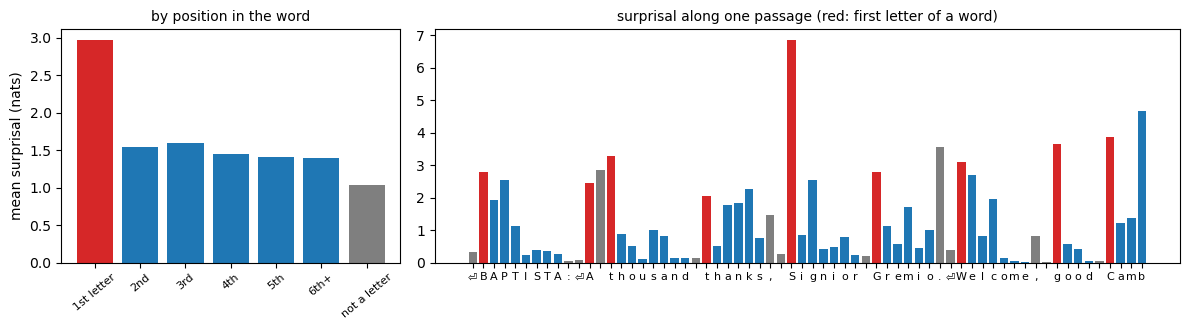

In [16]:
nll = model.nll(val_ids)                       # (32 streams, L): nll[r, s] is the cost of character r*L + s + 1
L_str = nll.shape[1]
val_text = ''.join(chars[i] for i in val_ids)
pos = canon.word_position(val_text)
pos_of = np.array([pos[r * L_str + s + 1] for r in range(nll.shape[0]) for s in range(L_str)]).reshape(nll.shape)
cats = [('1st letter', pos_of == 0), ('2nd', pos_of == 1), ('3rd', pos_of == 2), ('4th', pos_of == 3),
        ('5th', pos_of == 4), ('6th+', pos_of >= 5), ('not a letter', pos_of == -1)]
means = [float(nll[sel].mean()) for _, sel in cats]
for (name, sel), mval in zip(cats, means):
    print(f'{name:13s} {mval:.3f} nats   ({int(sel.sum()):,} characters)')

line_start = val_text.index('\n', 2000) + 1
seg = slice(line_start, line_start + 64)
r0, s0 = divmod(line_start - 1, L_str)
trace = nll[r0, s0:s0 + 64]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1, 2.2]})
axes[0].bar(range(len(cats)), means, color=['tab:red'] + ['tab:blue'] * 5 + ['tab:grey'])
axes[0].set_xticks(range(len(cats)), [c for c, _ in cats], rotation=40, fontsize=8)
axes[0].set_ylabel('mean surprisal (nats)'); axes[0].set_title('by position in the word', fontsize=10)
axes[1].bar(range(64), trace, color=['tab:red' if pos[line_start + k] == 0 else 'tab:blue' if pos[line_start + k] > 0
                                     else 'tab:grey' for k in range(64)])
axes[1].set_xticks(range(64), [c if c != '\n' else '⏎' for c in val_text[seg]], fontsize=8)
axes[1].set_title('surprisal along one passage (red: first letter of a word)', fontsize=10)
plt.tight_layout(); plt.show()
assert means[0] > 1.6 * max(means[1:6])

The first letter of a word costs the model about twice what any later letter does — nearly 3 nats
against 1.4 to 1.6 — and along the passage the red bars, word onsets, stand up like Elman's error
peaks. Once a word has begun, its continuation is constrained by spelling; which word comes next is
constrained only by meaning, and that is where most of the model's remaining uncertainty lives.
(Spaces and punctuation are cheapest of all: after a complete word, a space is usually a safe bet.)

### How far back does the gradient need to reach in text?

§4 found that an echo needs a gradient reaching back at least as far as the delay. Text is full of
dependencies at every distance — the letters of a word, the words of a line, a speaker's name at
the top of a speech. Train the same model for three epochs with its gradient cut every $k$
characters inside each 64-character chunk: $k = 1$ (Elman), 4, 16, and no cut. The state still
carries across everything; only the training signal's reach changes.

(0s)
gradient reaches back      1: validation loss after 3 epochs 2.216 -> 2.083 -> 1.994
gradient reaches back      4: validation loss after 3 epochs 2.165 -> 2.029 -> 1.940
gradient reaches back     16: validation loss after 3 epochs 2.195 -> 2.047 -> 1.967
gradient reaches back all 64: validation loss after 3 epochs 2.186 -> 2.048 -> 1.969


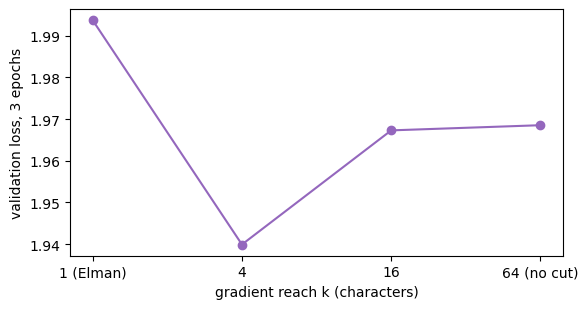

best to worst: 0.054 nats


In [17]:
t0 = time.time()
trunc_runs = {k: canon.run_char(epochs=3, lr_drops=(), truncate=k, data=data, cache=True) for k in (1, 4, 16, 0)}
print(f'({time.time() - t0:.0f}s)')
for k, (_, vl, h3) in trunc_runs.items():
    print(f"gradient reaches back {'all 64' if k == 0 else k:>6}: validation loss after 3 epochs "
          + ' -> '.join(f"{h['val_loss']:.3f}" for h in h3))
fig, ax = plt.subplots(figsize=(6, 3.2))
ks = [1, 4, 16, 64]
ax.plot(ks, [trunc_runs[k if k < 64 else 0][1] for k in ks], 'o-', c='tab:purple')
ax.set_xscale('log', base=2); ax.set_xticks(ks, ['1 (Elman)', '4', '16', '64 (no cut)'])
ax.set_xlabel('gradient reach k (characters)'); ax.set_ylabel('validation loss, 3 epochs')
plt.tight_layout(); plt.show()
spread = max(v[1] for v in trunc_runs.values()) - min(v[1] for v in trunc_runs.values())
print(f'best to worst: {spread:.3f} nats')
assert trunc_runs[0][1] < trunc_runs[1][1] and spread < 0.1

Hardly at all. After three epochs the four runs end within about 0.05 nats of one another —
roughly the size of the difference between two runs with different seeds. Elman's one-step
gradient comes last, and a 4-character reach first. That is §6's lesson, on real data: almost
everything a character model learns early is **supervised at every step** — the next character is
the target at every position, and most of what predicts it (the spelling of the current word,
the last few characters) is only a step or two back. Like the counter, such structure needs no long
gradient. The long-range part of language — a speaker's name governing a whole speech, a rhyme
closing a couplet — is exactly what the echo toy showed a plain recurrent network struggling to
learn, and it is a small share of the loss.

## 9. Why not just count? What a table of n-grams would need

The n-gram baseline stores one count for every context it has seen. Here is how many distinct
contexts the training text contains at each length, against the RNN's fixed parameter count.

contexts of  1 characters seen in training:        65
contexts of  2 characters seen in training:     1,380
contexts of  3 characters seen in training:    11,228
contexts of  4 characters seen in training:    48,539   <- the best n-gram conditions on 4
contexts of  5 characters seen in training:   133,293
contexts of  6 characters seen in training:   264,623
contexts of  7 characters seen in training:   413,620
contexts of  8 characters seen in training:   559,503
contexts of  9 characters seen in training:   684,640
contexts of 10 characters seen in training:   780,165
the RNN: 99,137 parameters, and a context as long as the text


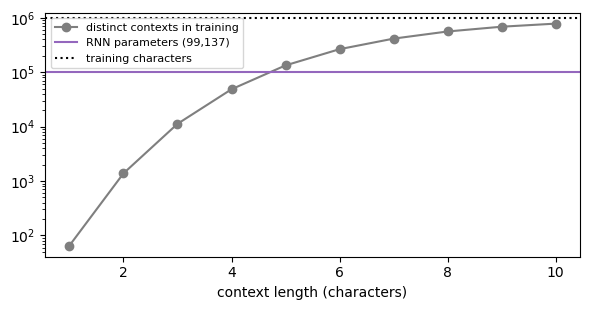

In [18]:
def distinct(ids, n):
    c = np.zeros(ids.size - n + 1, dtype=np.int64)
    for k in range(n):
        c = c * V_CH + ids[k:ids.size - n + 1 + k]
    return np.unique(c).size

ctx = {n: distinct(train_ids, n) for n in range(1, 11)}
for n, k in ctx.items():
    print(f'contexts of {n:2d} characters seen in training: {k:9,}' + ('   <- the best n-gram conditions on 4' if n == 4 else ''))
print(f'the RNN: {n_par:,} parameters, and a context as long as the text')
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(list(ctx), list(ctx.values()), 'o-', c='tab:grey', label='distinct contexts in training')
ax.axhline(n_par, c='tab:purple', label=f'RNN parameters ({n_par:,})')
ax.axhline(train_ids.size, c='black', ls=':', label='training characters')
ax.set_xlabel('context length (characters)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

By ten characters of context almost every position in the training text is a context of its own:
the table would have nearly as many entries as there are characters, each seen about once, which is
why the n-gram's validation loss turns upward after four. The recurrent network compresses all of
its history into 256 numbers and uses the same 99,137 parameters whatever the context length.
That trade — a fixed-size learned summary instead of an exponentially growing table — is the whole
case for recurrent language models, and Bengio's neural language model (2003) and Mikolov's RNN
language model (2010) made it against the n-gram systems that dominated speech recognition and
translation until then.

## 10. Export for the animation

In [19]:
def sub(xs, n=150):
    xs = np.asarray(xs, dtype=float)
    return np.round(xs[np.linspace(0, xs.size - 1, min(n, xs.size)).astype(int)], 5).tolist()

pick = np.random.default_rng(0).choice(proj.shape[0], 600, replace=False)
cliff_step = 4
payload = {
    'echo': {'delay': canon.DELAY,
             'bptt_loss': sub(twins[0]['loss']), 'elman_loss': sub(twins[1]['loss']),
             'bptt_curve': [list(map(float, p)) for p in twins[0]['curve']],
             'elman_curve': [list(map(float, p)) for p in twins[1]['curve']]},
    'reach': {'ks': ['1', '2', '4', '8', 'all'], 'ds': list(DS), 'acc': np.round(reach, 3).tolist()},
    'delay_sweep': {'delays': list(DELAYS), 'acc': np.round(delay_acc.mean(1), 3).tolist()},
    'text_reach': {str(k): round(v[1], 4) for k, v in trunc_runs.items()},
    'grad_init': {str(g): sub(gtt_init[g], 40) for g in GAINS},
    'grad_trained': {str(d): sub(gtt_trained[d], 40) for d in gtt_trained},
    'cliff': {'w': np.round(ws[::cliff_step], 3).tolist(), 'b': np.round(bs[::cliff_step], 3).tolist(),
              'loss': np.round(L_grid[::cliff_step, ::cliff_step], 4).tolist(),
              'path_none': np.round(paths[None][0][:40], 3).tolist(), 'path_clip': np.round(paths[1.0][0][::5], 3).tolist()},
    'counting': {'pc': np.round(proj[pick], 3).tolist(), 'count': yc.reshape(-1)[pick].astype(int).tolist(),
                 'acc': {str(T): round(a, 4) for T, a in count_acc[1].items()}},
    'char': {'val_loss': [round(h['val_loss'], 4) for h in hist], 'ngram': {str(n): round(l, 4) for n, (l, _) in ngram.items()},
             'samples': {str(e + 1): hist[e]['sample'][:220] for e in (0, 2, 9, len(hist) - 1)},
             'surprisal_text': val_text[seg], 'surprisal': np.round(trace, 3).tolist(),
             'by_position': dict(zip([c for c, _ in cats], np.round(means, 3).tolist()))},
    'canonical': {'bptt_acc': fp[0]['acc'], 'elman_acc': fp[1]['acc'], 'val_loss': round(val_loss, 4), 'params': int(n_par)},
}
canon.export_assets(payload)

[export] wrote C:\Users\shaia\development\deep-learning-from-scratch\topics\06-rnn\anim\rnn_assets.json


## 11. Framework mirrors: PyTorch, TensorFlow, Keras

The mechanisms were built from scratch above. This closing section shows the same ideas
idiomatically in each framework and **validates** ours against them — PyTorch strictly (same ops,
same numbers, gradient for gradient), TensorFlow and Keras at the result level.

### 11.1 PyTorch — our RNN *is* `nn.RNN`, our truncation is `.detach()`

In [20]:
import torch
import torch.nn.functional as F
rng = np.random.default_rng(10)

# (a) The layer: nn.RNN stores its weights transposed (out x in) and keeps TWO biases,
# b_ih and b_hh -- a cuDNN convention; they are always added together, so each gets the
# same gradient. Ours: Wxh = W_ih^T, Whh = W_hh^T, bh = b_ih + b_hh.
T, m, n_in, n_h = 9, 4, 5, 6
lay = ng.RNN(n_in, n_h)
for p in lay.params():
    p[...] = rng.standard_normal(p.shape) * 0.5
Xa, h0a, dHa = rng.standard_normal((T, m, n_in)), rng.standard_normal((m, n_h)) * 0.5, rng.standard_normal((T, m, n_h))
Ha = lay.forward(Xa, h0a); dXa = lay.backward(dHa)
trnn = torch.nn.RNN(n_in, n_h, nonlinearity='tanh').double()
with torch.no_grad():
    trnn.weight_ih_l0.copy_(torch.tensor(lay.Wxh.T)); trnn.weight_hh_l0.copy_(torch.tensor(lay.Whh.T))
    trnn.bias_ih_l0.copy_(torch.tensor(lay.bh)); trnn.bias_hh_l0.zero_()
Xt, h0t = torch.tensor(Xa, requires_grad=True), torch.tensor(h0a[None], requires_grad=True)
Ht, _ = trnn(Xt, h0t); Ht.backward(torch.tensor(dHa))
for name, ours, t in [('H', Ha, Ht.detach()), ('dX', dXa, Xt.grad), ('dh0', lay.dh0, h0t.grad[0]),
                      ('dWxh', lay.dWxh, trnn.weight_ih_l0.grad.T), ('dWhh', lay.dWhh, trnn.weight_hh_l0.grad.T),
                      ('dbh', lay.dbh, trnn.bias_ih_l0.grad), ('dbh (b_hh)', lay.dbh, trnn.bias_hh_l0.grad)]:
    err = rel_error(ours, t.numpy()); print(f'(a) {name:10s} rel_error = {err:.1e}'); assert err < 1e-12

# (b) Truncation: cut the graph every k steps with .detach(), the idiomatic way to train in chunks.
k = 3
lay.forward(Xa, h0a); lay.backward(dHa, truncate=k)
trnn.zero_grad(); h, loss = h0t.detach(), 0.0
for s in range(0, T, k):
    out, h = trnn(Xt[s:s + k].detach(), h.detach())        # the state flows on; the gradient stops here
    loss = loss + (out * torch.tensor(dHa[s:s + k])).sum()
loss.backward()
err = max(rel_error(lay.dWxh, trnn.weight_ih_l0.grad.T.numpy()), rel_error(lay.dWhh, trnn.weight_hh_l0.grad.T.numpy()))
print(f'(b) truncate={k} vs .detach() every {k} steps: rel_error = {err:.1e}'); assert err < 1e-12

# (c) Clipping: torch.nn.utils.clip_grad_norm_ is the same rule, except that it divides by
# (norm + 1e-6) -- so it lands a hair under max_norm.
gs = [rng.standard_normal((4, 5)) * 3, rng.standard_normal(7) * 3]
tp = [torch.zeros(g.shape, dtype=torch.float64, requires_grad=True) for g in gs]
for p, g in zip(tp, gs):
    p.grad = torch.tensor(g)
tn = float(torch.nn.utils.clip_grad_norm_(tp, 2.0)); on = ng.clip_grad_norm(gs, 2.0)
err = max(rel_error(g, p.grad.numpy()) for g, p in zip(gs, tp))
print(f'(c) clip: norms {on:.12f} vs {tn:.12f}; clipped gradients rel_error = {err:.1e}'); assert abs(on - tn) < 1e-12 and err < 1e-6

# (d) The character model, one truncated-BPTT update: every gradient vs autograd.
cm = canon.CharRNN(V_CH, 32, seed=3, dtype=np.float64)
xs, ys = val_ids[:24 * 5].reshape(5, 24).T, val_ids[1:24 * 5 + 1].reshape(5, 24).T
h0c = np.random.default_rng(4).standard_normal((5, 32)) * 0.3
loss_ours, _ = cm.loss_and_grads(xs, ys, h0c)
P_t = [torch.tensor(p, requires_grad=True) for p in cm.params()]
Wxh_t, Whh_t, bh_t, Why_t, by_t = P_t
h, logits = torch.tensor(h0c), []
for t in range(24):
    h = torch.tanh(Wxh_t[torch.tensor(xs[t])] + h @ Whh_t + bh_t)    # one-hot @ Wxh = a row of Wxh
    logits.append(h @ Why_t + by_t)
loss_t = F.cross_entropy(torch.cat(logits), torch.tensor(ys.reshape(-1)))
loss_t.backward()
err = max(rel_error(g, p.grad.numpy()) for g, p in zip(cm.grads(), P_t))
print(f'(d) char model: loss {loss_ours:.10f} vs {loss_t.item():.10f}; worst of 5 gradients rel_error = {err:.1e}')
assert abs(loss_ours - loss_t.item()) < 1e-9 and err < 1e-10   # (the loss's 1e-12 floor in the log)
print('PyTorch agrees: same recurrence, same backpropagation through time, same truncation, same clipping.')

(a) H          rel_error = 2.8e-14
(a) dX         rel_error = 6.9e-15
(a) dh0        rel_error = 1.1e-15
(a) dWxh       rel_error = 8.9e-15
(a) dWhh       rel_error = 2.9e-15
(a) dbh        rel_error = 1.1e-15
(a) dbh (b_hh) rel_error = 1.7e-15
(b) truncate=3 vs .detach() every 3 steps: rel_error = 2.9e-14
(c) clip: norms 19.133941388372 vs 19.133941388372; clipped gradients rel_error = 2.6e-08
(d) char model: loss 4.2705514391 vs 4.2705514392; worst of 5 gradients rel_error = 4.6e-13
PyTorch agrees: same recurrence, same backpropagation through time, same truncation, same clipping.


### 11.2 TensorFlow — the echo toy with `SimpleRNN`, a `GradientTape` and `clip_by_global_norm`

TensorFlow's recurrent layer is `tf.keras.layers.SimpleRNN` (one bias, weights stored as ours are,
`kernel` = $W_{xh}$ and `recurrent_kernel` = $W_{hh}$, batch-major inputs), and Pascanu's clipping is
`tf.clip_by_global_norm`. Same task, same recipe: echo the symbol from four steps back.

In [21]:
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import tensorflow as tf
tf.random.set_seed(0)
cell = tf.keras.layers.SimpleRNN(16, return_sequences=True, kernel_initializer=tf.keras.initializers.GlorotNormal(0),
                                 recurrent_initializer=tf.keras.initializers.GlorotNormal(1))
read = tf.keras.layers.Dense(4, kernel_initializer=tf.keras.initializers.GlorotNormal(2))
opt_tf = tf.keras.optimizers.Adam(0.01)
D = canon.DELAY

@tf.function
def tf_step(x, y):
    with tf.GradientTape() as tape:
        logits = read(cell(x))[:, D:]
        loss = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True))
    tvars = cell.trainable_variables + read.trainable_variables
    grads, _ = tf.clip_by_global_norm(tape.gradient(loss, tvars), 1.0)       # Pascanu clipping
    opt_tf.apply_gradients(zip(grads, tvars))
    return loss

gen = np.random.default_rng(0)
t0 = time.time()
for _ in range(600):
    Sb = gen.integers(0, 4, size=(32, 24))                                   # batch-major
    tf_step(tf.one_hot(Sb, 4), Sb[:, :-D])
St = np.random.default_rng(1).integers(0, 4, size=(256, 96))
pred = read(cell(tf.one_hot(St, 4))).numpy()[:, D:].argmax(-1)
tf_acc = float((pred == St[:, :-D]).mean())
print(f'TensorFlow SimpleRNN echo (d = {D}): test accuracy on 96-step sequences = {tf_acc:.4f}  ({time.time() - t0:.0f}s)')
assert tf_acc >= 0.99

TensorFlow SimpleRNN echo (d = 4): test accuracy on 96-step sequences = 1.0000  (2s)


### 11.3 Keras — a character model in six lines

In Keras the whole Shakespeare model is a `Sequential` stack. The one-hot input times $W_{xh}$ is an
`Embedding` (a learned row lookup — exactly what multiplying a one-hot vector by a matrix does),
followed by `SimpleRNN(256, return_sequences=True)` and a `Dense` read-out at every step. Two Keras
idioms differ from our loop: the model is **stateless** — each 64-character window starts from a
zero state, instead of carrying the state through the text — and clipping is an optimizer
argument, where `global_clipnorm` is Pascanu's rule (`clipnorm`, its neighbour, clips each weight
matrix *separately*, a different thing).

In [22]:
import keras
from keras import layers
keras.utils.set_random_seed(0)
W = 64
def windows(ids):
    n = (ids.size - 1) // W
    return ids[:n * W].reshape(n, W), ids[1:n * W + 1].reshape(n, W)
xtr, ytr = windows(train_ids); xva, yva = windows(val_ids)
km = keras.Sequential([keras.Input((None,), dtype='int32'),
                       layers.Embedding(V_CH, 64),
                       layers.SimpleRNN(256, return_sequences=True),
                       layers.Dense(V_CH)])
km.compile(optimizer=keras.optimizers.Adam(2e-3, global_clipnorm=5.0),
           loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
print(f'Keras char model: {km.count_params():,} parameters')
t0 = time.time()
km.fit(xtr, ytr, batch_size=64, epochs=4, shuffle=True, verbose=0)
keras_val = km.evaluate(xva, yva, batch_size=256, verbose=0)
print(f'Keras SimpleRNN validation loss = {keras_val:.4f} nats/char after 4 epochs ({time.time() - t0:.0f}s); '
      f'the trigram scores {ngram[3][0]:.4f}')
assert keras_val < ngram[3][0]

Keras char model: 103,041 parameters


Keras SimpleRNN validation loss = 1.8299 nats/char after 4 epochs (56s); the trigram scores 2.0458


---

**What we built.** A recurrent layer — the tanh recurrence over a whole sequence, and
backpropagation through time, with optional truncation — and gradient-norm clipping joined
`nanograd` in C and Python, agreeing to the last printed digit on the echo toy. Backpropagation
through time turned out to be two rules we already had: a state used twice gets the sum of both
gradients (Module 05's fork), and a weight used at every step gets the sum of every step's share
(Module 03's weight sharing). The toys showed what a recurrent network can and cannot learn: it
learns to remember only as far back as its training gradient reaches, and that gradient shrinks
or grows geometrically through time — while a task whose every step's target *is* the state, like
counting, needs almost no reach at all. On Shakespeare, 99,137 parameters and a 256-number state
beat every n-gram table, wrote passable stage directions and verse-shaped lines, and rediscovered
Elman's word boundaries.

**Next → Module 07 (LSTM):** the vanishing gradient through time is not a tuning problem — Bengio,
Simard and Frasconi proved that a plain recurrent network that stores information robustly must
also forget its gradients. Hochreiter and Schmidhuber's answer (1997) was a different cell: a
memory that is *added to* rather than rewritten at every step, with gates that decide what to
write, keep and read. Along that memory the gradient is multiplied by (nearly) exactly one — a
shortcut through time, eighteen years before ResNet's shortcut through depth.